In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

# Option A paths (using your mounted Google Drive file system paths):
# Note: Please adjust the folder paths below if your files are in a different Drive folder.
TRAIN_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTrain+.txt"
TEST_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTest+.txt"


In [4]:
import gdown

# Extract the file IDs from your Google Drive links
train_id = '1gEgDi6QPGiiK0ttYiBNk55ZTgUykX2UT'
test_id = '1YHacgPxgXudvMJyfLVzXkJl2OuY8D_QD'

# Define local destination paths
TRAIN_PATH = '/content/drive/MyDrive/KDDTrain+.txt'
TEST_PATH = '/content/drive/MyDrive/KDDTest+.txt'

# Download the files programmatically
# gdown.download(id=train_id, output=TRAIN_PATH, quiet=False)
# gdown.download(id=test_id, output=TEST_PATH, quiet=False)


In [7]:
def load_data(path):
    """Load an NSL-KDD file (no header) and name its columns."""
    try:
        df = pd.read_csv(path, names=COLUMNS)
    except FileNotFoundError:
        raise FileNotFoundError(f"File not found: {path}. Check the path.")
    if df.shape[1] != len(COLUMNS):
        raise ValueError(f"Expected {len(COLUMNS)} columns, got {df.shape[1]}.")
    return df

# Using the local paths downloaded by gdown in the previous step
train = load_data('/content/drive/MyDrive/KDDTrain+.txt')
test = load_data('/content/drive/MyDrive/KDDTest+.txt')
print(train.shape, test.shape)
display(train.head())


(125973, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0\ttcp\tftp_data\tSF\t491\t0\t0\t0\t0\t0\t0\t0...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0\tudp\tother\tSF\t146\t0\t0\t0\t0\t0\t0\t0\t0...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0\ttcp\tprivate\tS0\t0\t0\t0\t0\t0\t0\t0\t0\t0...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0\ttcp\thttp\tSF\t232\t8153\t0\t0\t0\t0\t0\t1\...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0\ttcp\thttp\tSF\t199\t420\t0\t0\t0\t0\t0\t1\t...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# audit checks

# Load train and test (tab-separated, no header)
train = pd.read_csv(TRAIN_PATH, names=COLUMNS, sep="\t")
test = pd.read_csv(TEST_PATH, names=COLUMNS, sep="\t")

# Quality checks for train and test
for name, df in [("train", train), ("test", test)]:
    is_normal = df["label"].str.lower() == "normal"   # works for 'normal' and 'Normal'
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print("missing values:", df.isna().sum().sum())
    print("duplicate rows:", df.duplicated().sum())
    print("normal %:", round(is_normal.mean() * 100, 2))
    print("attack %:", round((~is_normal).mean() * 100, 2))
    print()

# Columns that contain missing values (test file)
print("Columns with missing values:")
print(test.isna().sum()[lambda s: s > 0])

# Label counts
print("\nTrain label counts:")
print(train["label"].value_counts())
print("\nTest label counts:")
print(test["label"].value_counts())

# Categorical columns (train)
for col in ["protocol_type", "service", "flag"]:
    print(f"\n{col}: {train[col].nunique()} distinct values")

    test.isna().sum()[lambda s: s > 0]

--- train ---
shape: (125973, 43)
missing values: 0
duplicate rows: 0
normal %: 53.46
attack %: 46.54

--- test ---
shape: (22544, 43)
missing values: 22544
duplicate rows: 3
normal %: 43.08
attack %: 56.92

Columns with missing values:
difficulty    22544
dtype: int64

Train label counts:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

Test label counts:
label
Attack    12833
Normal     9711
Name: count, dtype: int64

protocol_type: 3 

In [9]:
!pip install -q gradio

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42   # a fixed number, so the results are the same every time
print("Libraries ready")

Libraries ready


In [11]:
# ── Visual theme ─────────────────────────────────────────────────────────────
# One palette and one chart style, used by every chart, table and card below.
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display
import html as _html

C = dict(normal="#14b8a6", attack="#f43f5e", accent="#6366f1",
         ink="#0f172a", muted="#64748b", grid="#e2e8f0", soft="#f1f5f9")

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["grid"], "axes.labelcolor": C["muted"],
    "axes.titlecolor": C["ink"], "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 14,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "axes.axisbelow": True,
    "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"],
    "xtick.major.size": 0, "ytick.major.size": 0,
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "legend.frameon": False,
})
CMAP_DIVERGING = LinearSegmentedColormap.from_list("div", [C["accent"], "#f8fafc", C["attack"]])
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#f8fafc", C["accent"]])


def page_header(title, subtitle=""):
    """A gradient banner that marks the start of a notebook section."""
    display(HTML(f"""
    <div style="background:linear-gradient(120deg,#4f46e5,#7c3aed);color:#fff;padding:18px 22px;
                border-radius:14px;margin:6px 0 10px;font-family:system-ui,-apple-system,Segoe UI,sans-serif">
      <div style="font-size:19px;font-weight:700;letter-spacing:-.01em">{_html.escape(title)}</div>
      <div style="font-size:13px;opacity:.85;margin-top:3px">{_html.escape(subtitle)}</div>
    </div>"""))


def metric_cards(items, title=""):
    """Show a row of KPI tiles. items = [(label, value_text, tone)], tone: good / bad / neutral."""
    tones = {"good": C["normal"], "bad": C["attack"], "neutral": C["accent"]}
    tiles = "".join(
        f"""<div style="flex:1;min-width:110px;background:#fff;border:1px solid {C['grid']};
                        border-top:3px solid {tones[t]};border-radius:10px;padding:10px 14px">
              <div style="font-size:11px;color:{C['muted']};text-transform:uppercase;letter-spacing:.06em">{_html.escape(l)}</div>
              <div style="font-size:21px;font-weight:700;color:{C['ink']};margin-top:2px">{_html.escape(v)}</div>
            </div>""" for l, v, t in items)
    head = (f"<div style='font-weight:600;color:{C['ink']};margin:8px 0 6px'>{_html.escape(title)}</div>"
            if title else "")
    display(HTML(f"<div style='font-family:system-ui,-apple-system,Segoe UI,sans-serif'>{head}"
                 f"<div style='display:flex;gap:10px;flex-wrap:wrap'>{tiles}</div></div>"))


print("Theme ready")

Theme ready


In [10]:
# OPTION A: you uploaded the files with the folder icon on the left of Colab
TRAIN_PATH = "/content/drive/MyDrive/KDDTrain+.txt"
TEST_PATH = "/content/drive/MyDrive/KDDTest+.txt"

# OPTION B: the files are in Google Drive.
# Remove the # at the start of the next 4 lines and put a # in front of the 2 lines above.
# from google.colab import drive
# drive.mount("/content/drive")
# TRAIN_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTrain+.txt"
# TEST_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTest+.txt"

In [6]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty",
]

FEATURES = COLUMNS[:41]                                # the 41 input columns
CATEGORICAL = ["protocol_type", "service", "flag"]     # text columns
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]


def load_data(path):
    """Read one NSL-KDD file (tab-separated, no header) and name its columns."""
    try:
        df = pd.read_csv(path, names=COLUMNS, sep="\t")
    except FileNotFoundError:
        raise FileNotFoundError(f"File not found: {path}. Check the path in Step 2.")
    if df["label"].isna().all():
        raise ValueError("All labels are empty: wrong separator or wrong file.")
    return df


train_raw = load_data(TRAIN_PATH)
test_raw = load_data(TEST_PATH)
print("Train:", train_raw.shape, "| Test:", test_raw.shape)
train_raw.head()

Train: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [12]:
FAMILY_MAP = {
    "normal": "Normal",
    # DoS: flooding a server so it stops working
    "neptune": "DoS", "smurf": "DoS", "back": "DoS", "teardrop": "DoS", "pod": "DoS", "land": "DoS",
    # Probe: scanning a network to find weaknesses
    "satan": "Probe", "ipsweep": "Probe", "portsweep": "Probe", "nmap": "Probe",
    # R2L: an outsider trying to get access
    "warezclient": "R2L", "guess_passwd": "R2L", "warezmaster": "R2L", "imap": "R2L",
    "ftp_write": "R2L", "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    # U2R: a normal user trying to get admin rights
    "buffer_overflow": "U2R", "rootkit": "U2R", "loadmodule": "U2R", "perl": "U2R",
}


def clean_data(df, name):
    """Clean one DataFrame and print a short report."""
    print(f"--- Cleaning {name} ---")
    df = df.copy()
    rows_before = len(df)

    # 1. Remove the difficulty column
    df = df.drop(columns=["difficulty"], errors="ignore")

    # 2. Tidy text columns
    for col in CATEGORICAL + ["label"]:
        df[col] = df[col].astype(str).str.strip()
    df["label"] = df["label"].str.lower()          # 'Normal' and 'normal' become the same

    # 3. Number columns must be numbers
    for col in NUMERIC:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # 4. Missing values
    n_missing = int(df.isna().any(axis=1).sum())
    print("Rows with missing values removed:", n_missing)
    df = df.dropna()

    # 5. Duplicate rows
    n_dup = int(df.duplicated().sum())
    print("Duplicate rows removed:", n_dup)
    df = df.drop_duplicates()

    # 6. Impossible values (negative numbers)
    negative = (df[NUMERIC] < 0).any(axis=1)
    print("Rows with negative values removed:", int(negative.sum()))
    df = df[~negative]

    # 7. Targets
    df["target"] = (df["label"] != "normal").astype(int)      # 0 = normal, 1 = attack
    df["family"] = df["label"].map(FAMILY_MAP)                # empty for the test file (only Normal/Attack)

    print(f"Rows: {rows_before} -> {len(df)}")
    return df.reset_index(drop=True)


train = clean_data(train_raw, "train")
test = clean_data(test_raw, "test")

# 8. Columns that never change carry no information, so we remove them
constant_cols = [c for c in NUMERIC if train[c].nunique() == 1]
print("\nConstant columns removed:", constant_cols)
train = train.drop(columns=constant_cols)
test = test.drop(columns=constant_cols)
NUMERIC = [c for c in NUMERIC if c not in constant_cols]
FEATURES = CATEGORICAL + NUMERIC

print("\nFinal number of input features:", len(FEATURES))
print("Train normal/attack:", train["target"].value_counts().to_dict())
print("Test normal/attack:", test["target"].value_counts().to_dict())

--- Cleaning train ---
Rows with missing values removed: 0
Duplicate rows removed: 0
Rows with negative values removed: 0
Rows: 125973 -> 125973
--- Cleaning test ---
Rows with missing values removed: 0
Duplicate rows removed: 3
Rows with negative values removed: 0
Rows: 22544 -> 22541

Constant columns removed: ['num_outbound_cmds']

Final number of input features: 40
Train normal/attack: {0: 67343, 1: 58630}
Test normal/attack: {1: 12830, 0: 9711}


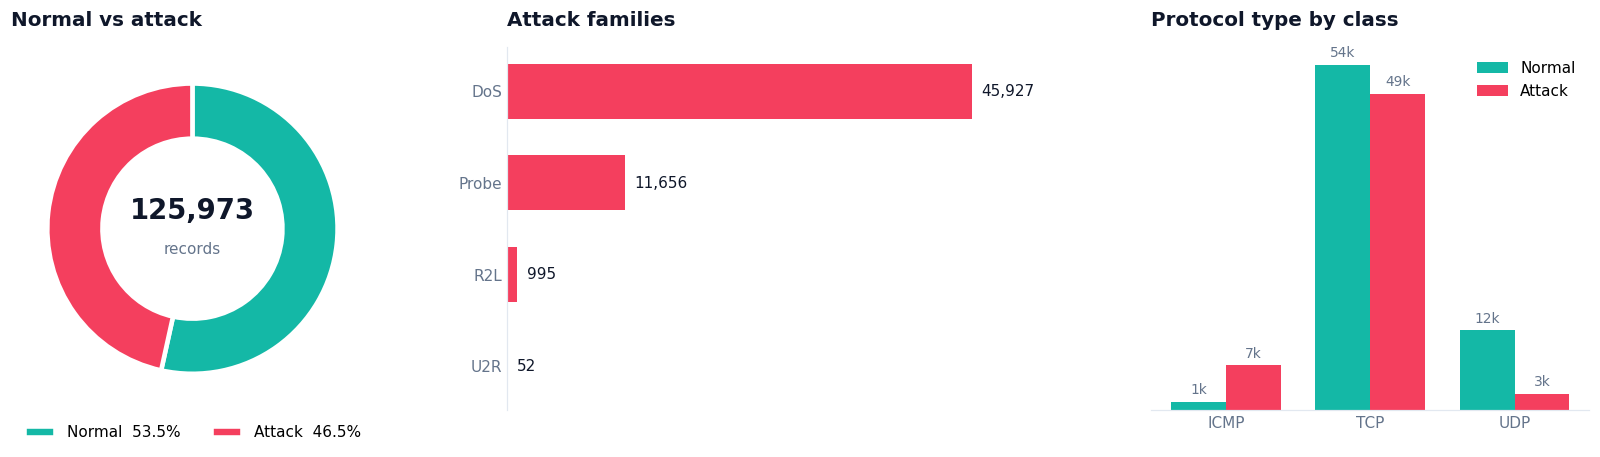

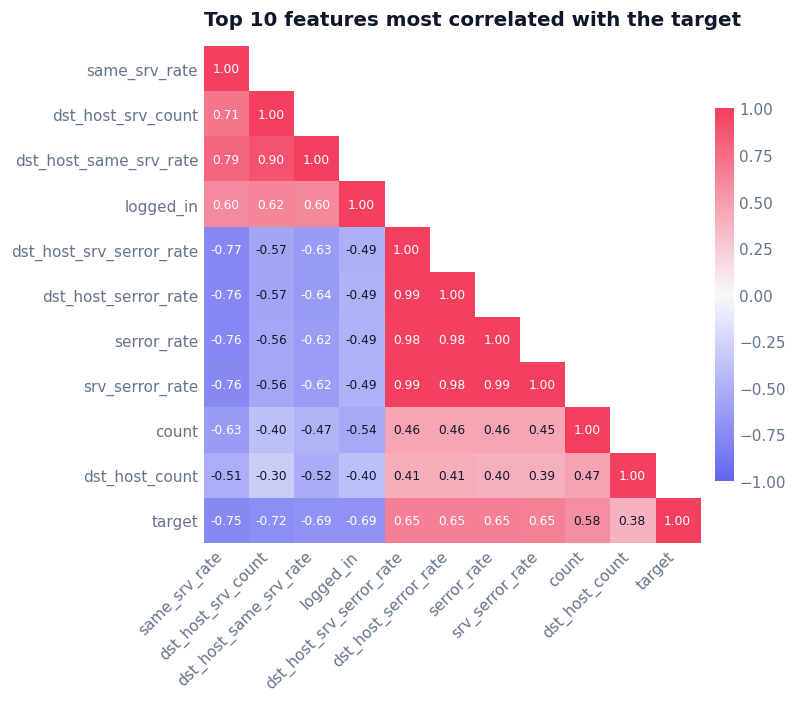

In [13]:
page_header("Exploring the training data", "Class balance, attack families, protocols and the strongest signals")

# ── Row of three overview charts ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.25, 1]})

# 1. Normal vs attack (donut)
ax = axes[0]
counts = train["target"].value_counts().sort_index()
ax.pie(counts.values, colors=[C["normal"], C["attack"]], startangle=90, counterclock=False,
       wedgeprops=dict(width=0.38, edgecolor="white", linewidth=3))
ax.text(0, 0.07, f"{len(train):,}", ha="center", fontsize=18, fontweight="bold", color=C["ink"])
ax.text(0, -0.17, "records", ha="center", fontsize=10, color=C["muted"])
ax.legend([f"Normal  {counts[0] / counts.sum():.1%}", f"Attack  {counts[1] / counts.sum():.1%}"],
          loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("Normal vs attack")

# 2. Attack families (horizontal bars)
ax = axes[1]
fam = train[train["target"] == 1]["family"].value_counts().sort_values()
bars = ax.barh(fam.index, fam.values, color=C["attack"], height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in fam.values], padding=6, color=C["ink"], fontsize=10)
ax.set_xlim(0, fam.max() * 1.18)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_title("Attack families")

# 3. Protocol type by class (grouped bars)
ax = axes[2]
proto = pd.crosstab(train["protocol_type"], train["target"])
proto.columns = ["Normal", "Attack"]
x = np.arange(len(proto))
w = 0.38
b1 = ax.bar(x - w / 2, proto["Normal"], w, color=C["normal"], label="Normal")
b2 = ax.bar(x + w / 2, proto["Attack"], w, color=C["attack"], label="Attack")
ax.bar_label(b1, labels=[f"{v / 1000:.0f}k" for v in proto["Normal"]], padding=3, fontsize=9, color=C["muted"])
ax.bar_label(b2, labels=[f"{v / 1000:.0f}k" for v in proto["Attack"]], padding=3, fontsize=9, color=C["muted"])
ax.set_xticks(x, [p.upper() for p in proto.index])
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)
ax.legend(loc="upper right")
ax.set_title("Protocol type by class")

fig.tight_layout(w_pad=3)
plt.show()

# ── Chart 4: which numeric features move with the target ────────────────────
top_cols = train[NUMERIC].corrwith(train["target"]).abs().sort_values(ascending=False).head(10).index.tolist()
corr = train[top_cols + ["target"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)          # show the lower triangle only
shown = np.ma.array(corr.values, mask=mask)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(shown, cmap=CMAP_DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else C["ink"])
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
cb.outline.set_visible(False)
cb.ax.tick_params(size=0)
ax.set_title("Top 10 features most correlated with the target")
fig.tight_layout()
plt.show()

In [14]:
X_all = train[FEATURES]
y_all = train["target"]

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE
)

X_test = test[FEATURES]
y_test = test["target"]

print("Training part:  ", X_train.shape)
print("Validation part:", X_val.shape)
print("Official test:  ", X_test.shape)


def build_pipeline(model):
    """Text columns -> numbers (one-hot), then the model."""
    prep = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough",     # number columns are used as they are
    )
    return Pipeline([("prep", prep), ("model", model)])

Training part:   (100778, 40)
Validation part: (25195, 40)
Official test:   (22541, 40)


In [16]:
results = []   # every result goes into this list


def evaluate(name, model, X, y, split_name):
    """Show the scores and a confusion matrix, and store the results."""
    pred = model.predict(X)
    cm = confusion_matrix(y, pred)
    tn, fp, fn, tp = cm.ravel()
    row = {
        "Model": name,
        "Data": split_name,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "False positive rate": fp / (fp + tn),
    }
    results.append(row)

    metric_cards([
        ("Accuracy", f"{row['Accuracy']:.1%}", "neutral"),
        ("Precision", f"{row['Precision']:.1%}", "neutral"),
        ("Recall", f"{row['Recall']:.1%}", "good" if row["Recall"] >= 0.9 else "bad"),
        ("F1", f"{row['F1']:.1%}", "neutral"),
        ("False positive rate", f"{row['False positive rate']:.1%}", "good" if row["False positive rate"] <= 0.05 else "bad"),
    ], title=f"{name} · {split_name}")

    # Confusion matrix: counts, plus the share of each true class
    pct = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.6, 3.9))
    ax.imshow(pct, cmap=CMAP_SEQ, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{pct[i, j]:.1%}", ha="center", va="center",
                    fontsize=12, fontweight="bold", color="white" if pct[i, j] > 0.55 else C["ink"])
    ax.set_xticks([0, 1], ["Normal", "Attack"])
    ax.set_yticks([0, 1], ["Normal", "Attack"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Confusion matrix · {split_name}", pad=34)
    fig.tight_layout()
    plt.show()

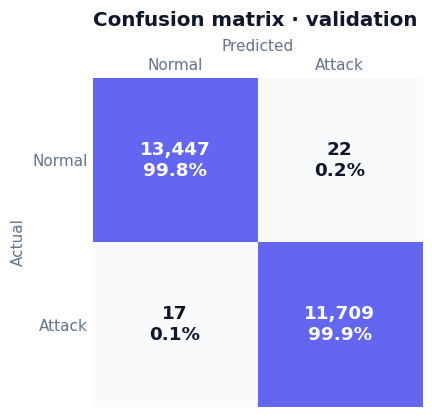

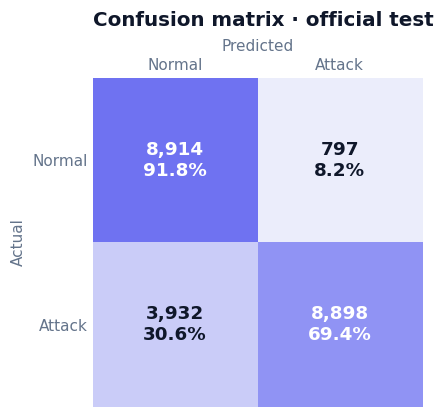

In [17]:
# Experiment 1: Decision Tree (baseline)
tree_model = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
tree_model.fit(X_train, y_train)
evaluate("Exp 1: Decision Tree", tree_model, X_val, y_val, "validation")
evaluate("Exp 1: Decision Tree", tree_model, X_test, y_test, "official test")

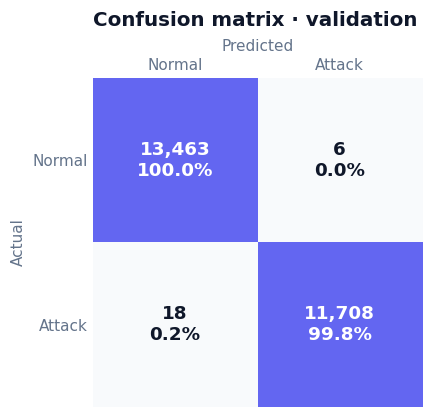

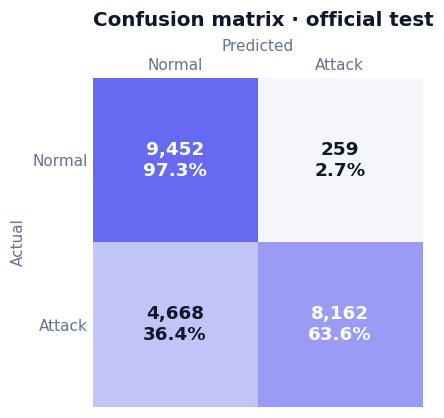

In [18]:
# Experiment 2: Random Forest (100 trees)
rf_model = build_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
rf_model.fit(X_train, y_train)
evaluate("Exp 2: Random Forest", rf_model, X_val, y_val, "validation")
evaluate("Exp 2: Random Forest", rf_model, X_test, y_test, "official test")

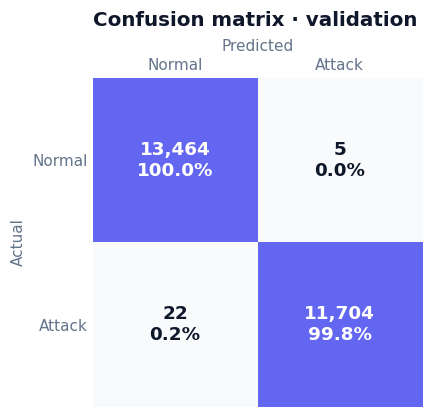

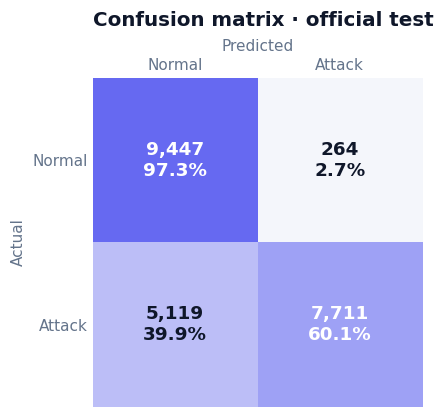

In [19]:
# Experiment 3: Random Forest (200 trees, balanced class weights)
rf_model_2 = build_pipeline(RandomForestClassifier(
    n_estimators=200, min_samples_leaf=2, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1))
rf_model_2.fit(X_train, y_train)
evaluate("Exp 3: Random Forest balanced", rf_model_2, X_val, y_val, "validation")
evaluate("Exp 3: Random Forest balanced", rf_model_2, X_test, y_test, "official test")

In [20]:
# Results table: copy this into your report
results_table = pd.DataFrame(results).round(4)
score_cols = ["Accuracy", "Precision", "Recall", "F1"]

(results_table.style
    .hide(axis="index")
    .format({c: "{:.1%}" for c in score_cols + ["False positive rate"]})
    .background_gradient(cmap=CMAP_SEQ, subset=score_cols, vmin=0.5, vmax=1.0)
    .background_gradient(cmap=LinearSegmentedColormap.from_list("fpr", ["#f8fafc", C["attack"]]),
                         subset=["False positive rate"], vmin=0, vmax=0.3)
    .set_table_styles([
        {"selector": "th", "props": [("background", C["ink"]), ("color", "white"), ("padding", "8px 14px"),
                                     ("text-align", "left"), ("font-weight", "600")]},
        {"selector": "td", "props": [("padding", "8px 14px"), ("border-bottom", f"1px solid {C['grid']}"),
                                     ("color", C["ink"])]},
    ])
    .set_properties(subset=["Model", "Data"], **{"font-weight": "600"}))

Model,Data,Accuracy,Precision,Recall,F1,False positive rate
Exp 1: Decision Tree,validation,99.9%,99.8%,99.9%,99.8%,0.2%
Exp 1: Decision Tree,official test,79.0%,91.8%,69.3%,79.0%,8.2%
Exp 2: Random Forest,validation,99.9%,100.0%,99.9%,99.9%,0.0%
Exp 2: Random Forest,official test,78.1%,96.9%,63.6%,76.8%,2.7%
Exp 3: Random Forest balanced,validation,99.9%,100.0%,99.8%,99.9%,0.0%
Exp 3: Random Forest balanced,official test,76.1%,96.7%,60.1%,74.1%,2.7%


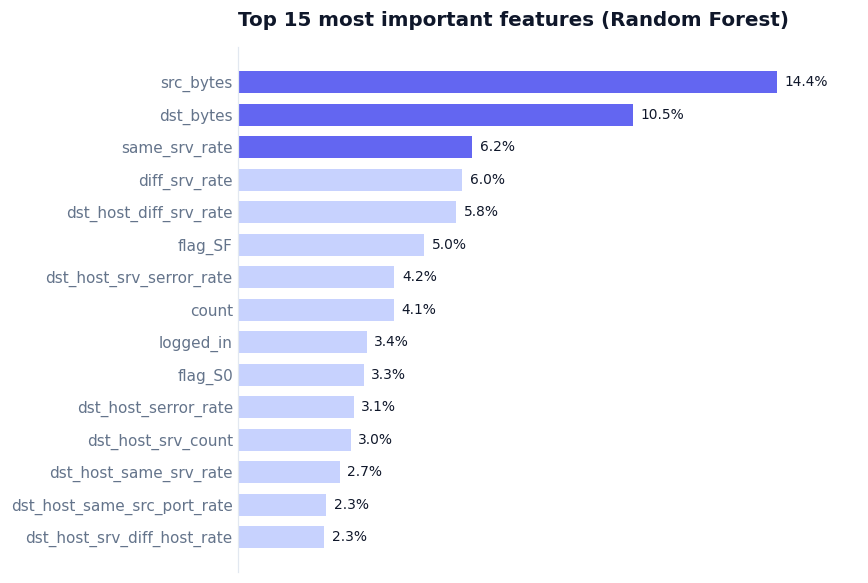

In [21]:
# The final model is the Random Forest from Experiment 2.
# To use Experiment 3 instead, change this line to: final_model = rf_model_2
final_model = rf_model

prep = final_model.named_steps["prep"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
importances = pd.Series(final_model.named_steps["model"].feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 5.4))
colors = [C["accent"] if i >= len(top15) - 3 else "#c7d2fe" for i in range(len(top15))]   # top 3 stand out
bars = ax.barh(top15.index, top15.values, color=colors, height=0.68)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in top15.values], padding=5, fontsize=9, color=C["ink"])
ax.set_xlim(0, top15.max() * 1.15)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_title("Top 15 most important features (Random Forest)")
fig.tight_layout()
plt.show()

In [22]:
ATTACK_THRESHOLD = 0.5      # attack probability at or above this = "Attack"


def alert_level(prob):
    """Turn an attack probability into a simple alert level."""
    if prob >= 0.90:
        return "High"
    if prob >= 0.50:
        return "Medium"
    return "Low"


def predict_connections(df, model=None):
    """Check the input, then predict normal/attack for every row."""
    model = model if model is not None else final_model

    if df is None or len(df) == 0:
        raise ValueError("The file is empty.")

    missing_cols = [c for c in FEATURES if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns: {missing_cols}")

    X = df[FEATURES].copy()
    for col in NUMERIC:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    if X[NUMERIC].isna().any().any():
        raise ValueError("Some number columns contain text or empty values.")
    if (X[NUMERIC] < 0).any().any():
        raise ValueError("Negative values were found. Please check the data.")

    prob = model.predict_proba(X)[:, 1]
    return pd.DataFrame({
        "row": np.arange(1, len(X) + 1),
        "protocol_type": X["protocol_type"].values,
        "service": X["service"].values,
        "flag": X["flag"].values,
        "prediction": np.where(prob >= ATTACK_THRESHOLD, "Attack", "Normal"),
        "attack_probability": prob.round(4),
        "alert_level": [alert_level(p) for p in prob],
    })

In [23]:
## Edge-case tests: what happens with bad input? Write what you see in your report.
sample = X_val.head(3).copy()

missing_column = sample.drop(columns=["src_bytes"])

new_category = sample.copy()
new_category["service"] = "brand_new_service"      # a value never seen in training

empty_data = X_val.head(0)

text_in_number = sample.copy()
text_in_number["duration"] = text_in_number["duration"].astype(object)
text_in_number.iloc[0, text_in_number.columns.get_loc("duration")] = "abc"

cases = {
    "1. Missing column": missing_column,
    "2. New category value": new_category,
    "3. Empty file": empty_data,
    "4. Text in a number column": text_in_number,
}

for name, data in cases.items():
    try:
        out = predict_connections(data)
        print(f"{name} -> OK, predictions: {out['prediction'].tolist()}")
    except Exception as e:
        print(f"{name} -> handled error: {e}")

1. Missing column -> handled error: Missing columns: ['src_bytes']
2. New category value -> OK, predictions: ['Attack', 'Normal', 'Attack']
3. Empty file -> handled error: The file is empty.
4. Text in a number column -> handled error: Some number columns contain text or empty values.


In [24]:
joblib.dump(final_model, "nids_random_forest.joblib")
train.to_csv("train_cleaned.csv", index=False)
test.to_csv("test_cleaned.csv", index=False)
print("Saved: nids_random_forest.joblib, train_cleaned.csv, test_cleaned.csv")

# To download them to your computer (so you can upload them to GitHub), remove the # below:
# from google.colab import files
# files.download("nids_random_forest.joblib")
# files.download("train_cleaned.csv")
# files.download("test_cleaned.csv")

Saved: nids_random_forest.joblib, train_cleaned.csv, test_cleaned.csv


In [25]:
# Helper functions for the GUI
DEFAULTS = {c: float(X_train[c].median()) for c in NUMERIC}           # typical value for every number column
DEFAULTS.update({c: X_train[c].mode()[0] for c in CATEGORICAL})       # most common value for every text column

PROTOCOLS = sorted(X_train["protocol_type"].unique().tolist())
SERVICES = sorted(X_train["service"].unique().tolist())
FLAGS = sorted(X_train["flag"].unique().tolist())

# One-click scenarios for the "Check one connection" tab
PRESETS = {
    "normal": ("tcp", "http", "SF", 200, 1000, 5, 0.0, True),         # everyday web browsing
    "syn":    ("tcp", "private", "S0", 0, 0, 300, 1.0, False),        # SYN flood: half-open connections
    "smurf":  ("icmp", "ecr_i", "SF", 1032, 0, 500, 0.0, False),      # ICMP echo flood
}


# ── HTML building blocks (styled by APP_CSS in the next cell) ───────────────
def esc(x):
    return _html.escape(str(x))


def empty_card(message):
    return f'<div class="nids-empty">{esc(message)}</div>'


def error_card(message):
    return f'<div class="nids-card nids-attack"><div class="nids-verdict">Something went wrong</div><p class="nids-note">{esc(message)}</p></div>'


def result_card(prediction, prob, level, extra=""):
    tone = "attack" if prediction == "Attack" else "normal"
    title = "Attack detected" if prediction == "Attack" else "Looks normal"
    return f"""
    <div class="nids-card nids-{tone}">
      <div class="nids-verdict"><span class="nids-dot"></span>{title}</div>
      <div class="nids-prob">{prob * 100:.1f}<small>%</small></div>
      <div class="nids-sub">attack probability</div>
      <div class="nids-meter"><div class="nids-fill" style="width:{prob * 100:.1f}%"></div>
        <div class="nids-tick" style="left:{ATTACK_THRESHOLD * 100:.0f}%"></div></div>
      <div class="nids-scale"><span>0%</span><span>threshold {ATTACK_THRESHOLD:.0%}</span><span>100%</span></div>
      <div class="nids-chips"><span class="nids-chip nids-lvl-{level.lower()}">{level} alert</span></div>
      {extra}
    </div>"""


def stat_tiles(items):
    """items = [(label, value, tone)]"""
    return '<div class="nids-tiles">' + "".join(
        f'<div class="nids-tile nids-t-{t}"><span>{esc(l)}</span><b>{esc(v)}</b></div>' for l, v, t in items
    ) + "</div>"


# ── Functions the GUI calls ──────────────────────────────────────────────────
def check_one(protocol, service, flag, src_bytes, dst_bytes, conn_count, serror_rate, logged_in):
    """Predict for one connection. Fields not shown in the form use typical values."""
    row = dict(DEFAULTS)
    row.update({
        "protocol_type": protocol, "service": service, "flag": flag,
        "src_bytes": src_bytes or 0, "dst_bytes": dst_bytes or 0,
        "count": conn_count or 0, "logged_in": int(logged_in),
    })
    # A SYN flood raises all four SYN-error features together, so one slider sets them all
    for col in ["serror_rate", "srv_serror_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate"]:
        row[col] = serror_rate
    try:
        res = predict_connections(pd.DataFrame([row])).iloc[0]
    except Exception as e:
        return error_card(e)
    return result_card(res["prediction"], res["attack_probability"], res["alert_level"])


def load_preset(name):
    return PRESETS[name]


def read_uploaded_file(path):
    """Read an uploaded file, with or without a header row."""
    with open(path, "r", errors="ignore") as f:
        first_line = f.readline()
    if "duration" in first_line.lower():
        return pd.read_csv(path, sep=None, engine="python")
    df = pd.read_csv(path, sep=None, engine="python", header=None)
    n = df.shape[1]
    if n < 41 or n > len(COLUMNS):
        raise ValueError(f"Expected 41 to {len(COLUMNS)} columns, found {n}.")
    df.columns = COLUMNS[:n]
    return df


def check_file(file):
    """Predict for every row of an uploaded file."""
    if file is None:
        return empty_card("Upload a file to see the results."), pd.DataFrame()
    path = file.name if hasattr(file, "name") else file
    try:
        res = predict_connections(read_uploaded_file(path))
    except Exception as e:
        return error_card(e), pd.DataFrame()
    n = len(res)
    n_attack = int((res["prediction"] == "Attack").sum())
    levels = res["alert_level"].value_counts()
    summary = stat_tiles([
        ("Records checked", f"{n:,}", "neutral"),
        (f"Flagged as attack ({n_attack / n:.1%})", f"{n_attack:,}", "bad" if n_attack else "good"),
        ("High alerts", f"{int(levels.get('High', 0)):,}", "bad"),
        ("Medium", f"{int(levels.get('Medium', 0)):,}", "warn"),
        ("Low", f"{int(levels.get('Low', 0)):,}", "good"),
    ]) + '<p class="nids-note">The table shows the 500 highest-risk rows.</p>'
    return summary, res.sort_values("attack_probability", ascending=False).head(500)


def random_example():
    """Pick a real validation record and compare the model with the true label."""
    i = int(np.random.randint(len(X_val)))
    row = X_val.iloc[[i]]
    truth = "Attack" if y_val.iloc[i] == 1 else "Normal"
    res = predict_connections(row).iloc[0]
    correct = res["prediction"] == truth
    r = row.iloc[0]
    details = f"""
      <div class="nids-compare">
        <div><span>Real label</span><b>{truth}</b></div>
        <div><span>Model says</span><b>{res['prediction']}</b></div>
        <div class="nids-{'ok' if correct else 'bad'}"><span>Result</span><b>{'✓ Correct' if correct else '✗ Wrong'}</b></div>
      </div>
      <table class="nids-kv">
        <tr><td>Protocol</td><td>{esc(r['protocol_type'])}</td><td>Service</td><td>{esc(r['service'])}</td></tr>
        <tr><td>Flag</td><td>{esc(r['flag'])}</td><td>Count</td><td>{esc(r['count'])}</td></tr>
        <tr><td>Bytes sent</td><td>{esc(r['src_bytes'])}</td><td>Bytes received</td><td>{esc(r['dst_bytes'])}</td></tr>
      </table>"""
    return result_card(res["prediction"], res["attack_probability"], res["alert_level"], details)


def model_snapshot():
    """Headline numbers for the banner (official test set, final model)."""
    try:
        r = next(x for x in results if x["Model"].startswith("Exp 2") and x["Data"] == "official test")
        return stat_tiles([("Test accuracy", f"{r['Accuracy']:.1%}", "neutral"),
                           ("Attack recall", f"{r['Recall']:.1%}", "warn"),
                           ("False alarms", f"{r['False positive rate']:.1%}", "good"),
                           ("Features", str(len(FEATURES)), "neutral")])
    except StopIteration:
        return ""

In [26]:
# Launch the GUI
import gradio as gr
import inspect

APP_CSS = """
.gradio-container { max-width: 1120px !important; margin: auto; }
.nids-hero { background: linear-gradient(120deg,#4f46e5 0%,#7c3aed 55%,#db2777 100%); color:#fff;
             border-radius:18px; padding:26px 30px; margin-bottom:6px; }
.nids-hero h1 { margin:0; font-size:28px; font-weight:750; letter-spacing:-.02em; color:#fff; }
.nids-hero p { margin:6px 0 0; opacity:.9; font-size:14.5px; max-width:720px; line-height:1.5; color:#fff; }
.nids-badges { margin-top:14px; display:flex; gap:8px; flex-wrap:wrap; }
.nids-badges span { background:rgba(255,255,255,.18); border:1px solid rgba(255,255,255,.28);
                    padding:3px 11px; border-radius:99px; font-size:12px; }

.nids-tiles { display:flex; gap:10px; flex-wrap:wrap; margin:6px 0; }
.nids-tile { flex:1; min-width:120px; padding:11px 14px; border-radius:12px; border:1px solid var(--border-color-primary);
             background:var(--background-fill-secondary); box-shadow:inset 0 3px 0 #6366f1; }
.nids-tile span { display:block; font-size:11px; text-transform:uppercase; letter-spacing:.06em; opacity:.65; }
.nids-tile b { font-size:19px; white-space:nowrap; }
.nids-t-good { box-shadow:inset 0 3px 0 #14b8a6; } .nids-t-bad { box-shadow:inset 0 3px 0 #f43f5e; } .nids-t-warn { box-shadow:inset 0 3px 0 #f59e0b; }

.nids-card { border-radius:16px; padding:22px 24px; border:1px solid var(--border-color-primary);
             background:var(--background-fill-secondary); border-left:6px solid #14b8a6; }
.nids-card.nids-attack { border-left-color:#f43f5e; }
.nids-verdict { font-weight:700; font-size:14px; text-transform:uppercase; letter-spacing:.08em; color:#0d9488; display:flex; align-items:center; gap:8px; }
.nids-attack .nids-verdict { color:#e11d48; }
.nids-dot { width:10px; height:10px; border-radius:50%; background:#14b8a6; box-shadow:0 0 0 4px rgba(20,184,166,.25); }
.nids-attack .nids-dot { background:#f43f5e; box-shadow:0 0 0 4px rgba(244,63,94,.25); }
.nids-prob { font-size:60px; font-weight:800; line-height:1.05; margin-top:10px; letter-spacing:-.03em; }
.nids-prob small { font-size:26px; opacity:.6; margin-left:2px; }
.nids-sub { opacity:.65; font-size:13px; margin-bottom:14px; }
.nids-meter { position:relative; height:12px; border-radius:99px; background:var(--border-color-primary); overflow:visible; }
.nids-fill { height:100%; border-radius:99px; background:linear-gradient(90deg,#14b8a6,#f59e0b 55%,#f43f5e); }
.nids-tick { position:absolute; top:-4px; width:2px; height:20px; background:var(--body-text-color); opacity:.55; }
.nids-scale { display:flex; justify-content:space-between; font-size:11px; opacity:.55; margin-top:6px; }
.nids-chips { margin-top:14px; }
.nids-chip { display:inline-block; padding:4px 12px; border-radius:99px; font-size:12.5px; font-weight:600; }
.nids-lvl-low { background:#ccfbf1; color:#0f766e; } .nids-lvl-medium { background:#fef3c7; color:#b45309; }
.nids-lvl-high { background:#ffe4e6; color:#be123c; }

.nids-empty { border:2px dashed var(--border-color-primary); border-radius:16px; padding:46px 20px; text-align:center; opacity:.65; }
.nids-note { opacity:.65; font-size:13px; margin:8px 2px 0; }
.nids-compare { display:grid; grid-template-columns:repeat(3,1fr); gap:10px; margin-top:18px; }
.nids-compare div { padding:10px 12px; border-radius:10px; background:var(--background-fill-primary); border:1px solid var(--border-color-primary); }
.nids-compare span { display:block; font-size:11px; text-transform:uppercase; letter-spacing:.06em; opacity:.6; }
.nids-compare b { font-size:16px; } .nids-ok b { color:#0d9488; } .nids-bad b { color:#e11d48; }
.nids-kv, .nids-kv tr { border:none !important; }
.nids-kv { width:100%; margin-top:14px; border-collapse:collapse; font-size:13.5px; }
.nids-kv td { padding:6px 8px; border:none !important; border-bottom:1px solid var(--border-color-primary) !important; }
.nids-kv td:nth-child(odd) { opacity:.6; width:18%; }

.nids-footer { text-align:center; opacity:.55; font-size:12px; margin-top:10px; }
button.primary { font-weight:600 !important; }
"""

theme = gr.themes.Soft(
    primary_hue="indigo", secondary_hue="violet", neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "system-ui", "sans-serif"],
    radius_size="lg",
)

HERO = """
<div class="nids-hero">
  <h1>🛡️ Network Intrusion Detection</h1>
  <p>A classroom prototype that flags suspicious network connections using a Random Forest trained on
     NSL-KDD. It supports human review and must not be used for real security decisions.</p>
  <div class="nids-badges"><span>Random Forest</span><span>NSL-KDD</span><span>Prototype</span></div>
</div>"""

with gr.Blocks(title="Network Intrusion Detection System",
               **({} if "theme" in inspect.signature(gr.Blocks.launch).parameters else {"theme": theme, "css": APP_CSS})) as demo:
    gr.HTML(HERO)
    gr.HTML(model_snapshot())

    with gr.Tab("Check one connection"):
        gr.Markdown("Start with a preset, or tweak the fields yourself. Anything not shown here uses a typical value.")
        with gr.Row():
            btn_normal = gr.Button("🌐 Normal web browsing", size="sm")
            btn_syn = gr.Button("🌊 SYN flood", size="sm")
            btn_smurf = gr.Button("📡 ICMP (smurf) flood", size="sm")
        with gr.Row(equal_height=False):
            with gr.Column(scale=5):
                with gr.Group():
                    with gr.Row():
                        protocol = gr.Dropdown(PROTOCOLS, value="tcp", label="Protocol")
                        service = gr.Dropdown(SERVICES, value="http", label="Service")
                        flag = gr.Dropdown(FLAGS, value="SF", label="Flag (connection status)")
                with gr.Group():
                    with gr.Row():
                        src_bytes = gr.Number(value=200, label="Bytes sent (src_bytes)")
                        dst_bytes = gr.Number(value=1000, label="Bytes received (dst_bytes)")
                    conn_count = gr.Number(value=5, label="Connections to the same host in the last 2 seconds (count)")
                    serror_rate = gr.Slider(0, 1, value=0.0, step=0.05, label="SYN error rate (sets all 4 SYN-error features)")
                    logged_in = gr.Checkbox(value=True, label="Logged in")
                btn_one = gr.Button("Check connection", variant="primary", size="lg")
            with gr.Column(scale=4):
                out_one = gr.HTML(empty_card("Pick a preset or press “Check connection”."))

        inputs_one = [protocol, service, flag, src_bytes, dst_bytes, conn_count, serror_rate, logged_in]
        btn_one.click(check_one, inputs_one, out_one)
        for btn, key in [(btn_normal, "normal"), (btn_syn, "syn"), (btn_smurf, "smurf")]:
            btn.click(lambda k=key: load_preset(k), None, inputs_one).then(check_one, inputs_one, out_one)

    with gr.Tab("Check a file"):
        gr.Markdown("Upload a `.txt` or `.csv` file of connection records "
                    "(same columns as KDDTrain+.txt, with or without a header row).")
        with gr.Row(equal_height=False):
            with gr.Column(scale=3):
                file_in = gr.File(label="Connection records file", file_types=[".txt", ".csv"])
                btn_file = gr.Button("Check file", variant="primary", size="lg")
            with gr.Column(scale=5):
                out_summary = gr.HTML(empty_card("Upload a file to see the results."))
        out_table = gr.Dataframe(label="Results (highest risk first)", interactive=False, wrap=False)
        btn_file.click(check_file, file_in, [out_summary, out_table])

    with gr.Tab("Random real example"):
        gr.Markdown("Picks a real connection from the validation data and compares the model with the true label.")
        btn_rand = gr.Button("🎲 Show a random example", variant="primary", size="lg")
        out_rand = gr.HTML(empty_card("Press the button to draw a record."))
        btn_rand.click(random_example, None, out_rand)

    gr.HTML('<div class="nids-footer">Educational prototype · trained on NSL-KDD · not for production security decisions</div>')

launch_kwargs = {"share": True}
if "theme" in inspect.signature(gr.Blocks.launch).parameters:      # Gradio 6+ takes the look at launch time
    launch_kwargs.update(theme=theme, css=APP_CSS)
demo.launch(**launch_kwargs)    # prints a public link you can open and show in your demo

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0387fd6039530e010b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
